# ARIMA Forecasting & Monte Carlo Simulation

This notebook loads the processed data from the descriptive analysis notebook and runs ARIMA-based price forecasting with Monte Carlo simulations to identify the best-performing HDB resale flat combinations over the next 10 years.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from tqdm import tqdm
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error
import os
import pickle
import time
from IPython import get_ipython
from IPython.display import display, clear_output
import ipywidgets as widgets
import sys
from statsmodels.graphics.tsaplots import plot_acf

# Analysis parameters
config = {
    # Financial parameters
    'risk_free_rate': 2.7,  # Current risk-free rate (%)

    # Lease parameters
    'max_lease': 99,  # Maximum HDB lease in years
    'min_acceptable_lease': 35,  # Minimum lease considered good for resale

    # ROI score parameters
    'cagr_weight': 0.7,  # Weight for CAGR in ROI calculation
    'sharpe_weight': 0.2,  # Weight for Sharpe ratio in ROI calculation
    'lease_weight': 0.1,  # Weight for remaining lease in ROI calculation
    'sharpe_scaling_factor': 10,  # Scaling factor for Sharpe ratio
    'lease_scaling_factor': 25,  # Scaling factor for lease factor

    # ARIMA parameters
    'forecast_years': 10,  # Years to forecast into future
    'min_years_required': 10,  # Minimum years of data for ARIMA
    'max_reasonable_cagr': 10,  # Cap for CAGR predictions (%)
    'max_reasonable_price_multiplier': 3, # Multiplier for cap on reasonable price
    'validation_size': 0.2,  # Proportion of data for validation
    'mape_threshold': 30,  # Maximum acceptable MAPE (%)


    # Filtering parameters
    'recent_years_threshold': 2,  # Recent data threshold for towns

    # File paths
    'checkpoint_dir': 'checkpoints',
    'arima_models_file': 'checkpoints/arima_models.pkl',
    'predictions_file': 'checkpoints/arima_predictions.csv',
    'validation_file': 'checkpoints/arima_validation.csv'
}


# Load processed data from descriptive analysis notebook
import pickle

with open('checkpoints/descriptive_analysis_output.pkl', 'rb') as f:
    export_data = pickle.load(f)

df_filtered = export_data['df_filtered']
top_5_towns = export_data['top_5_towns']
top_roi_locations = export_data['top_roi_locations']
appreciation_df = export_data['appreciation_df']
town_year_prices = export_data['town_year_prices']

risk_free_rate = config['risk_free_rate']

print(f'Loaded processed data: {df_filtered.shape[0]:,} transactions across {len(top_5_towns)} top towns')
print(f'Top 5 towns: {top_5_towns}')


Loaded processed data: 947,306 transactions across 5 top towns
Top 5 towns: ['SEMBAWANG', 'SENGKANG', 'QUEENSTOWN', 'CENTRAL AREA', 'WOODLANDS']


# **ARIMA Model Functions**

In [5]:
# ============================================================================
# ARIMA MODEL FOR FUTURE PRICE PREDICTION AND ROI FORECAST
# ============================================================================

# Set time horizon for prediction
forecast_years = config['forecast_years']

# Create checkpoint directory if it doesn't exist
checkpoint_dir = config['checkpoint_dir']
if not os.path.exists(checkpoint_dir):
    os.makedirs(checkpoint_dir)

# Define checkpoint files
arima_models_file = config['arima_models_file']
predictions_file = config['predictions_file']
validation_file = config['validation_file']

# Create a function for displaying notebook progress
def display_progress(current, total, description="Progress", clear=True):
    """Display progress bar in Jupyter notebook or print text fallback"""

    # Check if running in a Jupyter environment that supports widgets
    is_notebook = False
    try:
        shell = get_ipython().__class__.__name__
        if shell == 'ZMQInteractiveShell':
            is_notebook = True   # Jupyter notebook or qtconsole
        elif shell == 'TerminalInteractiveShell':
            is_notebook = False  # Terminal running IPython
        else:
            is_notebook = False  # Other type (?)
    except NameError:
        is_notebook = False      # Probably standard Python interpreter
    except ImportError:
        is_notebook = False      # IPython not even installed

    if is_notebook:
        try:
            if clear:
                clear_output(wait=True)
            progress = widgets.FloatProgress(
                value=current,
                min=0,
                max=total,
                description=description,
                bar_style='info',
                style={'bar_color': '#0080ff'}
            )
            percentage = widgets.HTML(value=f"{100 * current / total:.2f}% ({current}/{total})")
            display(widgets.HBox([progress, percentage]))
        except Exception:
            # Fallback to print if widgets fail even in notebook
            print(f"{description}: {current}/{total} ({100 * current / total:.2f}%)")
    else:
        # Fallback to print if in a non-notebook environment (like nbconvert)
        # Simple progress update without clearing previous lines might be best here
        sys.stdout.write(f"\r{description}: {current}/{total} ({100 * current / total:.2f}%)")
        sys.stdout.flush()
        if current == total:
            sys.stdout.write("\n") # Add newline when complete

# Function to check stationarity
def check_stationarity(series):
    """Check if a time series is stationary using the Augmented Dickey-Fuller test"""
    result = adfuller(series)
    return result[1] < 0.05  # p-value less than 0.05 indicates stationarity

# Function to find optimal ARIMA parameters
def find_best_arima_params(series):
    """Find the best ARIMA parameters (p,d,q) for a time series using AIC"""
    best_aic = float('inf')
    best_params = None
    p_range = range(0, 3)
    d_range = range(0, 2)
    q_range = range(0, 3)

    # Make sure the series is sorted by index (year)
    series = series.sort_index()

    # Handle NaN values before fitting
    if series.isna().any():
        series = series.dropna()

    # Check if we have enough data points after cleaning
    if len(series) < 5:
        return (1, 1, 0)  # Default for short series

    for p in p_range:
        for d in d_range:
            for q in q_range:
                try:
                    model = ARIMA(series, order=(p, d, q))
                    results = model.fit()

                    if results.aic < best_aic:
                        best_aic = results.aic
                        best_params = (p, d, q)
                except Exception as e:
                    # Skip this combination silently
                    continue

    # If no model works, return a default configuration
    if best_params is None:
        return (1, 1, 0)

    return best_params

# Function to create and fit ARIMA model for price prediction
def fit_arima_model(time_series, order):
    """
    Fit an ARIMA model to the time series data with the specified order.

    Parameters:
    -----------
    time_series : pandas.Series
        Time series data with datetime index
    order : tuple
        ARIMA model order (p, d, q)

    Returns:
    --------
    model_fit : ARIMA model results
    """
    try:
        # Ensure time series is sorted by index and handle NaN values
        time_series = time_series.sort_index().dropna()

        # Create and fit the ARIMA model
        model = ARIMA(time_series, order=order)

        # Use fit without specific parameters for compatibility
        model_fit = model.fit()

        return model_fit
    except Exception as e:
        print(f"Error fitting ARIMA model: {e}")
        return None

# Add a new function to validate ARIMA models with train-test split
def validate_arima_model(time_series, order, validation_size=config['validation_size']):
    """
    Validate ARIMA model using train-test split

    Parameters:
    -----------
    time_series : pandas.Series
        Time series data with datetime index
    order : tuple
        ARIMA model order (p, d, q)
    validation_size : float
        Proportion of data to use for validation (default from config)

    Returns:
    --------
    dict: Dictionary containing validation metrics and forecasts
    """
    try:
        # Ensure time series is sorted by index and handle NaN values
        time_series = time_series.sort_index().dropna()

        # Compute the split point
        train_size = int(len(time_series) * (1 - validation_size))
        if train_size < 5:  # Need at least 5 points for training
            return None

        # Split into train and test sets
        train_data = time_series.iloc[:train_size]
        test_data = time_series.iloc[train_size:]

        # Create and fit the ARIMA model on training data
        model = ARIMA(train_data, order=order)
        model_fit = model.fit()

        # Forecast the test period
        forecast = model_fit.forecast(steps=len(test_data))

        # Calculate error metrics
        mse = mean_squared_error(test_data, forecast)
        rmse = np.sqrt(mse)

        # Calculate percentage error (MAPE)
        mape = np.mean(np.abs((test_data - forecast) / test_data)) * 100

        return {
            'mse': mse,
            'rmse': rmse,
            'mape': mape,
            'train_size': len(train_data),
            'test_size': len(test_data),
            'forecasts': forecast,
            'actuals': test_data
        }
    except Exception as e:
        print(f"Error validating ARIMA model: {e}")
        return None

def load_arima_checkpoints():
    """Load ARIMA predictions from checkpoint files"""
    if os.path.exists(predictions_file):
        print(f"Loading existing predictions from {predictions_file}")
        try:
            predictions_df = pd.read_csv(predictions_file)
            combo_predictions = predictions_df.to_dict('records')
            print(f"Loaded {len(combo_predictions)} predictions from checkpoint")

            # Check if the data is valid by ensuring key columns exist
            required_columns = ['town', 'flat_type', 'storey_category', 'predicted_roi_score']
            if all(col in predictions_df.columns for col in required_columns):
                print("Checkpoint data is valid.")
                return combo_predictions, predictions_df
            else:
                print("Checkpoint data is missing required columns. Will need to regenerate predictions.")
                return [], None
        except Exception as e:
            print(f"Error loading predictions: {e}")
            return [], None
    else:
        print("No existing predictions found. Will need to generate new predictions.")
        return [], None

def find_towns_with_sufficient_history(df_filtered, top_towns, min_years=10):
    """Find towns with sufficient historical data for ARIMA modeling"""
    towns_with_history = []
    for town in top_towns:
        town_data = df_filtered[df_filtered['town'] == town]
        yearly_prices = town_data.groupby('year')['price_per_sqm'].mean()

        if len(yearly_prices) >= min_years:
            towns_with_history.append(town)

    print(f"Found {len(towns_with_history)}/{len(top_towns)} towns with sufficient historical data")
    return towns_with_history

def count_valid_combinations(df_filtered, towns_list):
    """Count the number of valid town/flat_type/storey combinations for analysis"""
    total_combinations = 0

    for town in towns_list:
        town_data = df_filtered[df_filtered['town'] == town].copy()

        # Create storey categories if needed
        if 'storey_category' not in town_data.columns:
            town_data['storey_min'] = town_data['storey_range'].str.split(' TO ', expand=True)[0].astype(int)
            town_data['storey_max'] = town_data['storey_range'].str.split(' TO ', expand=True)[1].astype(int)
            town_data['storey_mid'] = (town_data['storey_min'] + town_data['storey_max']) / 2
            town_data['storey_category'] = pd.cut(
                town_data['storey_mid'],
                bins=[0, 5, 10, 15, 20, 25, 50],
                labels=['01-05', '06-10', '11-15', '16-20', '21-25', '26+']
            )

        flat_types = town_data['flat_type'].unique()

        for flat_type in flat_types:
            flat_data = town_data[town_data['flat_type'] == flat_type]
            storey_cats = flat_data['storey_category'].dropna().unique()

            for storey_cat in storey_cats:
                combo_data = flat_data[flat_data['storey_category'] == storey_cat]

                if len(combo_data) >= 15:
                    yearly_prices = combo_data.groupby('year')['price_per_sqm'].mean()

                    if len(yearly_prices) >= 10:
                        total_combinations += 1

    return total_combinations

def save_checkpoint(combo_predictions, saved_models, processed, total, validation_results=None):
    """Save checkpoint data to files"""
    # Save predictions to CSV
    if combo_predictions:
        temp_df = pd.DataFrame(combo_predictions)
        temp_df.to_csv(predictions_file, index=False)
        print(f"Saved {len(combo_predictions)} predictions to {predictions_file}")

    # Save validation results if provided
    if validation_results:
        # Remove non-serializable elements
        validation_results_clean = []
        for res in validation_results:
            if isinstance(res, dict):  # Ensure it's a dict before processing
                res_clean = {k: v for k, v in res.items() if k not in ['forecasts', 'actuals']}
                validation_results_clean.append(res_clean)

        if validation_results_clean:
            validation_df = pd.DataFrame(validation_results_clean)
            validation_df.to_csv(validation_file, index=False)
            print(f"Saved {len(validation_results_clean)} validation results to {validation_file}")

    # Save models to pickle file if not too large
    if saved_models:
        try:
            # First check if the pickle would be too large
            with open(arima_models_file + '.temp', 'wb') as f:
                pickle.dump(saved_models, f)

            # Check file size
            file_size = os.path.getsize(arima_models_file + '.temp') / (1024 * 1024 * 1024)  # Size in GB

            if file_size < 1.0:
                # If file is small enough, save it properly
                os.rename(arima_models_file + '.temp', arima_models_file)
                print(f"Saved {len(saved_models)} models to {arima_models_file} ({file_size:.2f} GB)")
            else:
                # File too large, remove temp file and skip model saving
                os.remove(arima_models_file + '.temp')
                print(f"Models file too large ({file_size:.2f} GB), skipping model checkpoint")
        except Exception as e:
            print(f"Error saving models: {e}")
            # Clean up temp file if it exists
            if os.path.exists(arima_models_file + '.temp'):
                os.remove(arima_models_file + '.temp')

    # Display progress
    display_progress(processed, total, description="Overall Progress")

def generate_arima_predictions(df_filtered, towns_with_history):
    """Generate ARIMA predictions for all valid combinations"""
    # Dictionary to store trained models for checkpointing
    saved_models = {}
    combo_predictions = []
    validation_results = []  # New list to store validation results

    # Count total combinations for progress tracking
    total_combinations = count_valid_combinations(df_filtered, towns_with_history)
    print(f"Found {total_combinations} combinations to analyze")

    if total_combinations == 0:
        print("No valid combinations found. Check your data requirements.")
        return [], pd.DataFrame()

    # Set up checkpointing interval
    checkpoint_interval = max(1, total_combinations // 10)  # Save after every ~10% of combinations
    last_checkpoint_time = time.time()
    checkpoint_time_interval = 300  # 5 minutes
    processed_combinations = 0

    # Create progress widget for notebook
    display_progress(0, total_combinations, "ARIMA Modeling Progress")

    # Set forecast years
    forecast_years = config['forecast_years']

    # Minimum years of data required for reliable ARIMA prediction
    min_years_required = config['min_years_required']

    # Now process each combination
    for town in towns_with_history:
        town_data = df_filtered[df_filtered['town'] == town].copy()

        # Create storey categories
        if 'storey_category' not in town_data.columns:
            town_data['storey_min'] = town_data['storey_range'].str.split(' TO ', expand=True)[0].astype(int)
            town_data['storey_max'] = town_data['storey_range'].str.split(' TO ', expand=True)[1].astype(int)
            town_data['storey_mid'] = (town_data['storey_min'] + town_data['storey_max']) / 2
            town_data['storey_category'] = pd.cut(
                town_data['storey_mid'],
                bins=[0, 5, 10, 15, 20, 25, 50],
                labels=['01-05', '06-10', '11-15', '16-20', '21-25', '26+']
            )

        # Define combinations of flat_type and storey_category
        flat_types = town_data['flat_type'].unique()

        # Analyze each flat type
        for flat_type in flat_types:
            flat_data = town_data[town_data['flat_type'] == flat_type]

            storey_cats = flat_data['storey_category'].dropna().unique()

            # Analyze each storey category
            for storey_cat in storey_cats:
                combo_data = flat_data[flat_data['storey_category'] == storey_cat]

                # Only proceed if we have enough data points
                if len(combo_data) < 15:
                    continue

                # Group by year to get annual average prices
                yearly_prices = combo_data.groupby('year')['price_per_sqm'].mean()

                # Skip if we don't have at least min_years_required years of data
                if len(yearly_prices) < min_years_required:
                    print(f"Skipping {town}, {flat_type}, {storey_cat}: Insufficient historical data ({len(yearly_prices)} years < {min_years_required} years required)")
                    continue

                # Generate combo key for model storage
                combo_key = f"{town}_{flat_type}_{storey_cat}"

                # Try to find optimal ARIMA parameters
                try:
                    # Make sure we're dealing with numeric data
                    if not np.issubdtype(yearly_prices.dtype, np.number):
                        yearly_prices = yearly_prices.astype(float)

                    # Convert the yearly index to a proper pandas datetime index
                    # This helps with forecasting and addresses the "unsupported index" warning
                    yearly_prices.index = pd.to_datetime(yearly_prices.index, format='%Y')

                    # Find best parameters with AIC criterion
                    best_params = find_best_arima_params(yearly_prices)

                    if best_params is None:
                        # Fall back to default parameters
                        best_params = (1, 1, 0)

                    # VALIDATE THE MODEL WITH TRAIN-TEST SPLIT
                    # Use the most recent 20% of data as validation set
                    validation_results_dict = validate_arima_model(yearly_prices, best_params, validation_size=config['validation_size'])

                    # Only proceed if validation was successful
                    if validation_results_dict is not None:
                        validation_results_dict['town'] = town
                        validation_results_dict['flat_type'] = flat_type
                        validation_results_dict['storey_category'] = storey_cat
                        validation_results_dict['model_order'] = str(best_params)
                        validation_results.append(validation_results_dict)

                        # Now fit on the full dataset for forecasting
                        model_fit = fit_arima_model(yearly_prices, order=best_params)

                        # Add validation metrics to tracking
                        mape = validation_results_dict['mape']
                        print(f"Validation MAPE for {town}, {flat_type}, {storey_cat}: {mape:.2f}%")

                        # If validation error is too high, consider skipping or using a different model
                        if mape > config['mape_threshold']:  # Skip combinations with error higher than threshold
                            print(f"Skipping {town}, {flat_type}, {storey_cat}: Validation error too high (MAPE: {mape:.2f}%)")
                            continue
                    else:
                        # If validation failed, fit on full dataset but note the lack of validation
                        print(f"Warning: Validation failed for {town}, {flat_type}, {storey_cat}. Proceeding without validation.")
                    model_fit = fit_arima_model(yearly_prices, order=best_params)

                    if model_fit is not None:
                        # Store the fitted model for later use
                        saved_models[combo_key] = model_fit

                        # Get model summary
                        forecast = model_fit.forecast(steps=forecast_years)

                        # Check for unreasonable forecast values (more than N times growth)
                        current_price = yearly_prices.iloc[-1]
                        # Use the value from the config dictionary
                        max_reasonable_price = current_price * config['max_reasonable_price_multiplier']

                        # If forecast is unreasonable, cap the values
                        future_price = forecast.iloc[-1]
                        if future_price > max_reasonable_price:
                            print(f"Warning: Capping unreasonable forecast for {town}, {flat_type}, {storey_cat}")
                            future_price = max_reasonable_price

                        # Calculate average remaining lease
                        avg_remaining_lease = combo_data['remaining_lease'].mean()

                        # Get current price and most recent transaction year
                        current_year = yearly_prices.index[-1].year

                        # Calculate predicted CAGR
                        if current_price > 0 and future_price > 0:
                            predicted_cagr = (((future_price / current_price) ** (1/forecast_years)) - 1) * 100

                            # Add a sanity check for CAGR (cap at reasonable maximum)
                            max_reasonable_cagr = config['max_reasonable_cagr']
                            if predicted_cagr > max_reasonable_cagr:
                                print(f"Warning: Capping unreasonable CAGR of {predicted_cagr:.2f}% to {max_reasonable_cagr}% for {town}, {flat_type}, {storey_cat}")
                                predicted_cagr = max_reasonable_cagr
                                # Recalculate future price based on capped CAGR
                                future_price = current_price * ((1 + (predicted_cagr/100)) ** forecast_years)
                        else:
                            # Skip this combination if prices are invalid
                            print(f"Warning: Invalid prices for {town}, {flat_type}, {storey_cat}")
                            continue

                        # Calculate predicted total growth
                        total_growth_pct = ((future_price / current_price) - 1) * 100

                        # Get volatility (standard deviation of yearly changes)
                        yearly_prices_change = yearly_prices.pct_change() * 100
                        volatility = yearly_prices_change.dropna().std()

                        # Calculate predicted Sharpe ratio using forecast volatility
                        predicted_sharpe = (predicted_cagr - risk_free_rate) / volatility if volatility > 0 else 0

                        # Calculate lease factor
                        predicted_lease_factor = (avg_remaining_lease - config['min_acceptable_lease']) / (config['max_lease'] - config['min_acceptable_lease'])
                        predicted_lease_factor = min(max(predicted_lease_factor, 0), 1)  # Clip between 0 and 1

                        # Calculate predicted ROI score using the same formula
                        predicted_roi_score = (
                            config['cagr_weight'] * predicted_cagr +
                            config['sharpe_weight'] * predicted_sharpe * config['sharpe_scaling_factor'] +
                            config['lease_weight'] * predicted_lease_factor * config['lease_scaling_factor']
                        )

                        # Add validation metrics to the prediction output
                        validation_mape = validation_results_dict['mape'] if validation_results_dict else None
                        validation_rmse = validation_results_dict['rmse'] if validation_results_dict else None

                        # Save forecast results
                        combo_predictions.append({
                            'town': town,
                            'flat_type': flat_type,
                            'storey_category': storey_cat,
                            'current_price': float(current_price),  # Convert to float for CSV serialization
                            'current_year': int(current_year),      # Convert to int for CSV serialization
                            'predicted_price': float(future_price), # Convert to float for CSV serialization
                            'forecast_year': int(current_year + forecast_years),
                            'predicted_cagr': float(predicted_cagr),
                            'total_growth_pct': float(total_growth_pct),
                            'volatility': float(volatility),
                            'predicted_sharpe': float(predicted_sharpe),
                            'avg_remaining_lease': float(avg_remaining_lease),
                            'predicted_lease_factor': float(predicted_lease_factor),
                            'predicted_roi_score': float(predicted_roi_score),
                            'model_order': str(best_params),  # Store as string for CSV storage
                            'years_of_data': int(len(yearly_prices)),  # Store how many years of data were used
                            'validation_mape': validation_mape,  # Include validation MAPE
                            'validation_rmse': validation_rmse   # Include validation RMSE
                        })
                except Exception as e:
                    # Skip combinations that cause errors
                    print(f"Error analyzing {town}, {flat_type}, {storey_cat}: {str(e)}")
                    continue

                # Update progress
                processed_combinations += 1
                display_progress(processed_combinations, total_combinations, "ARIMA Modeling Progress")

                # Check if it's time for a checkpoint
                current_time = time.time()
                time_elapsed = current_time - last_checkpoint_time

                if (processed_combinations % checkpoint_interval == 0) or (time_elapsed > checkpoint_time_interval):
                    print(f"\nCheckpoint: Processed {processed_combinations}/{total_combinations} combinations ({processed_combinations/total_combinations*100:.1f}%)")
                    save_checkpoint(combo_predictions, saved_models, processed_combinations, total_combinations, validation_results)

                    last_checkpoint_time = current_time

    # Final save of predictions
    save_checkpoint(combo_predictions, saved_models, processed_combinations, total_combinations, validation_results)

    # Convert to DataFrame
    if combo_predictions:
        predictions_df = pd.DataFrame(combo_predictions)
        return combo_predictions, predictions_df
    else:
        print("No valid predictions were generated.")
        return [], pd.DataFrame()

def plot_comparison_bar_chart(top_predicted_roi):
    """
    Create a bar chart comparing current vs predicted prices for top ROI combinations.

    Parameters:
    -----------
    top_predicted_roi : pandas.DataFrame
        DataFrame containing the top ROI combinations.
    """
    plt.figure(figsize=(14, 8))

    # Plot both current and predicted prices
    x = range(len(top_predicted_roi))
    width = 0.35

    # Create labels for x-axis
    labels = [f"{row['town']}\n{row['flat_type']}\n{row['storey_category']}"
              for _, row in top_predicted_roi.iterrows()]

    # Plot bars for current and predicted prices
    current_bars = plt.bar([i - width/2 for i in x], top_predicted_roi['current_price'],
                          width, label=f'Current Price ({top_predicted_roi["current_year"].iloc[0]})')

    predicted_bars = plt.bar([i + width/2 for i in x], top_predicted_roi['predicted_price'],
                            width, label=f'Predicted Price ({top_predicted_roi["forecast_year"].iloc[0]})')

    # Add percentage increase labels
    for i, (_, row) in enumerate(top_predicted_roi.iterrows()):
        plt.text(i - width/2, row['current_price'] + 50, f"${int(row['current_price'])}",
                ha='center', va='bottom', fontsize=8)

        # Add validation MAPE to the label if available
        validation_note = ""
        if 'validation_mape' in row and not pd.isna(row['validation_mape']):
            validation_note = f"\n(MAPE: {row['validation_mape']:.1f}%)"

        plt.text(i + width/2, row['predicted_price'] + 50,
                f"${int(row['predicted_price'])}\n(+{row['total_growth_pct']:.1f}%){validation_note}",
                ha='center', va='bottom', fontsize=8)

    plt.ylabel('Price per Square Meter (SGD)')
    plt.title('Current vs Predicted Prices for Top 10 ROI Combinations')
    plt.xticks(x, labels, rotation=45, ha='right')
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def plot_validation_metrics_histogram(predictions_df):
    """
    Create a histogram of validation MAPE values across all models.

    Parameters:
    -----------
    predictions_df : pandas.DataFrame
        DataFrame containing all prediction data with validation metrics.
    """
    # Check if validation_mape column exists
    if 'validation_mape' not in predictions_df.columns:
        print("Warning: No validation MAPE data found in the predictions DataFrame.")
        return

    # Drop NaN values and check if we have data to plot
    valid_mape = predictions_df['validation_mape'].dropna()
    if len(valid_mape) == 0:
        print("Warning: No valid validation MAPE values found (all are NaN).")
        return

    print(f"Found {len(valid_mape)} validation MAPE values to plot (out of {len(predictions_df)} total rows)")

    # Now we're sure we have data to plot
    plt.figure(figsize=(14, 6))
    sns.histplot(valid_mape, bins=20, kde=True)
    plt.title('Distribution of Validation MAPE Across All Models')
    plt.xlabel('Mean Absolute Percentage Error (%)')
    plt.ylabel('Count')

    # Add median line
    median_mape = valid_mape.median()
    plt.axvline(median_mape, color='red', linestyle='--',
               label=f'Median MAPE: {median_mape:.2f}%')

    # Add some statistics as text
    stats_text = (
        f"Min: {valid_mape.min():.2f}%\n"
        f"Max: {valid_mape.max():.2f}%\n"
        f"Mean: {valid_mape.mean():.2f}%\n"
        f"Median: {median_mape:.2f}%\n"
        f"Count: {len(valid_mape)}"
    )
    plt.annotate(stats_text, xy=(0.05, 0.95), xycoords='axes fraction',
                bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.8),
                fontsize=10, va="top")

    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_validation_metrics_histogram(predictions_df):
    """
    Create a histogram of validation MAPE values across all models.

    Parameters:
    -----------
    predictions_df : pandas.DataFrame
        DataFrame containing all prediction data with validation metrics.
    """
    # Check if validation_mape column exists
    if 'validation_mape' not in predictions_df.columns:
        print("Warning: No validation MAPE data found in the predictions DataFrame.")
        return

    # Drop NaN values and check if we have data to plot
    valid_mape = predictions_df['validation_mape'].dropna()
    if len(valid_mape) == 0:
        print("Warning: No valid validation MAPE values found (all are NaN).")
        return

    print(f"Found {len(valid_mape)} validation MAPE values to plot (out of {len(predictions_df)} total rows)")

    # Now we're sure we have data to plot
    plt.figure(figsize=(14, 6))
    sns.histplot(valid_mape, bins=20, kde=True)
    plt.title('Distribution of Validation MAPE Across All Models')
    plt.xlabel('Mean Absolute Percentage Error (%)')
    plt.ylabel('Count')

    # Add median line
    median_mape = valid_mape.median()
    plt.axvline(median_mape, color='red', linestyle='--',
               label=f'Median MAPE: {median_mape:.2f}%')

    # Add some statistics as text
    stats_text = (
        f"Min: {valid_mape.min():.2f}%\n"
        f"Max: {valid_mape.max():.2f}%\n"
        f"Mean: {valid_mape.mean():.2f}%\n"
        f"Median: {median_mape:.2f}%\n"
        f"Count: {len(valid_mape)}"
    )
    plt.annotate(stats_text, xy=(0.05, 0.95), xycoords='axes fraction',
                bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.8),
                fontsize=10, va="top")

    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_monte_carlo_forecast(top_combo):
    """
    Create a Monte Carlo simulation visualization for the top ROI combination.

    Parameters:
    -----------
    top_combo : pandas.Series
        Series containing data for the top ROI combination.
    """
    # Get the top combination details
    town = top_combo['town']
    flat_type = top_combo['flat_type']
    storey_cat = top_combo['storey_category']

    # Create a time series from current to forecast year
    current_year = int(top_combo['current_year'])
    forecast_year = int(top_combo['forecast_year'])
    years = list(range(current_year, forecast_year + 1))

    # Calculate price for each year based on CAGR (compound growth)
    current_price = top_combo['current_price']
    predicted_cagr = top_combo['predicted_cagr'] / 100  # Convert to decimal
    volatility = top_combo['volatility'] / 100  # Convert volatility to decimal

    # Main prediction with constant CAGR
    compound_prices = [current_price * ((1 + predicted_cagr) ** i) for i in range(len(years))]

    # Calculate simple interest (linear growth)
    annual_increase = current_price * predicted_cagr
    simple_prices = [current_price + (annual_increase * i) for i in range(len(years))]

    # ------- DATA-DRIVEN VARIABLE GROWTH PATTERN -------
    # Instead of arbitrary modifiers, use historical volatility to create realistic variations

    # First, get historical data for this combination to analyze actual growth patterns
    # Find the town data from the original dataset
    combo_key = f"{town}_{flat_type}_{storey_cat}"

    # Use volatility from historical data to generate realistic variations
    # Set random seed for reproducibility
    np.random.seed(420)

    # Generate variations based on historical volatility patterns
    # We'll use a random walk with the CAGR as drift and historical volatility as the standard deviation
    num_simulations = 1000
    all_simulations = []

    for _ in range(num_simulations):
        # Create random yearly growth rates based on historical volatility
        # Using normal distribution with mean=CAGR and std=volatility
        yearly_growth_rates = np.random.normal(predicted_cagr, volatility, len(years)-1)

        # Create price series for this simulation
        sim_prices = [current_price]
        for rate in yearly_growth_rates:
            # Ensure growth rate is not extremely negative (floor at -20%)
            rate = max(rate, -0.2)
            sim_prices.append(sim_prices[-1] * (1 + rate))

        all_simulations.append(sim_prices)

    # Convert to numpy array for easier calculations
    all_simulations = np.array(all_simulations)

    # Calculate median path and confidence intervals
    median_prices = np.median(all_simulations, axis=0)
    lower_bound_prices = np.percentile(all_simulations, 10, axis=0)  # 10th percentile
    upper_bound_prices = np.percentile(all_simulations, 90, axis=0)  # 90th percentile

    # Plot the price appreciation over time
    plt.figure(figsize=(14, 8))

    # Plot confidence interval as a shaded area
    plt.fill_between(years, lower_bound_prices, upper_bound_prices, alpha=0.2, color='blue',
                    label='80% Confidence Interval')

    # Plot the median simulation path
    plt.plot(years, median_prices, marker='^', linewidth=2, markersize=7,
             label='Median Price Path (Monte Carlo)', color='purple')

    # Plot the compound growth (CAGR) - our main prediction
    plt.plot(years, compound_prices, marker='o', linewidth=2, markersize=8,
             label='Compound Growth (Constant CAGR)', color='blue')

    # Add points and labels for start and end of main prediction
    plt.scatter([years[0], years[-1]], [compound_prices[0], compound_prices[-1]], color='red', s=100, zorder=5)
    plt.annotate(f"${int(compound_prices[0])}", xy=(years[0], compound_prices[0]), xytext=(5, 10),
                textcoords='offset points', fontsize=12, fontweight='bold')
    plt.annotate(f"${int(compound_prices[-1])}", xy=(years[-1], compound_prices[-1]), xytext=(5, 10),
                textcoords='offset points', fontsize=12, fontweight='bold')

    # Calculate yearly percentage increases for main prediction
    yearly_increases = [(compound_prices[i]/compound_prices[i-1] - 1) * 100 for i in range(1, len(compound_prices))]

    # Add percentage increase labels for main prediction
    for i in range(1, len(years)):
        plt.annotate(f"+{yearly_increases[i-1]:.1f}%", xy=(years[i], compound_prices[i]), xytext=(0, -15),
                    textcoords='offset points', fontsize=9, ha='center')

    # Add annotations for confidence interval bounds in the last year
    plt.annotate(f"Upper bound: ${int(upper_bound_prices[-1])}",
                xy=(years[-1], upper_bound_prices[-1]),
                xytext=(10, 0), textcoords='offset points',
                fontsize=9, color='darkblue')

    plt.annotate(f"Lower bound: ${int(lower_bound_prices[-1])}",
                xy=(years[-1], lower_bound_prices[-1]),
                xytext=(10, 0), textcoords='offset points',
                fontsize=9, color='darkblue')

    # Set title and labels
    plt.title(f'Predicted Price Appreciation for {town}, {flat_type}, {storey_cat}', fontsize=16, fontweight='bold')
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('Price per Square Meter (SGD)', fontsize=14)

    # Add gridlines for better readability
    plt.grid(True, linestyle='--', alpha=0.7)

    # Add legend
    plt.legend(loc='lower right', fontsize=10)

    # Add CAGR and total growth annotations with uncertainty
    total_growth = ((compound_prices[-1] / compound_prices[0]) - 1) * 100
    upper_growth = ((upper_bound_prices[-1] / current_price) - 1) * 100
    lower_growth = ((lower_bound_prices[-1] / current_price) - 1) * 100

    plt.annotate(f"CAGR: {predicted_cagr*100:.2f}% ± {volatility*100:.2f}%\n" +
                f"Total Growth: {total_growth:.2f}%\n" +
                f"Potential Range: {lower_growth:.1f}% to {upper_growth:.1f}%",
                xy=(0.05, 0.85), xycoords='axes fraction',
                bbox=dict(boxstyle="round,pad=0.5", fc="lightyellow", ec="orange", alpha=0.8),
                fontsize=12)

    # Add explanation of the models and uncertainty
    explanation_text = (
        "Growth Models and Uncertainty:\n"
        "• Blue Line: Constant CAGR of {:.2f}% annually\n"
        "• Purple Line: Median price path from Monte Carlo simulations\n"
        "• Shaded Area: 80% confidence interval based on historical volatility of {:.2f}%"
    ).format(predicted_cagr*100, volatility*100)

    plt.annotate(explanation_text,
                xy=(0.5, 0.02), xycoords='axes fraction',
                bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.8),
                fontsize=10, ha='center')

    # Add validation metrics if available
    if 'validation_mape' in top_combo and not pd.isna(top_combo['validation_mape']):
        plt.annotate(f"Model Validation MAPE: {top_combo['validation_mape']:.2f}%",
                    xy=(0.05, 0.95), xycoords='axes fraction',
                    bbox=dict(boxstyle="round,pad=0.5", fc="lightblue", ec="blue", alpha=0.8),
                    fontsize=12)

    plt.tight_layout()
    plt.show()

def plot_validation_vs_growth(predictions_df):
    """
    Plot the relationship between validation error (MAPE) and predicted growth (CAGR).

    Parameters:
    -----------
    predictions_df : pandas.DataFrame
        DataFrame containing all prediction data with validation metrics.
    """
    # Check if validation_mape column exists
    if 'validation_mape' not in predictions_df.columns:
        print("Warning: No validation MAPE data found in the predictions DataFrame.")
        return None

    # Drop NaN values and check if we have data to plot
    validation_mape = predictions_df['validation_mape'].dropna()
    if len(validation_mape) == 0:
        print("Warning: No valid validation MAPE values found (all are NaN).")
        return None

    # Get corresponding CAGR values
    predicted_cagr = predictions_df.loc[validation_mape.index, 'predicted_cagr']

    # Check if we have matching data
    if len(predicted_cagr) == 0:
        print("Warning: No matching CAGR values found for validation MAPE data.")
        return None

    # Now we're sure we have data to plot
    plt.figure(figsize=(10, 6))
    plt.scatter(validation_mape, predicted_cagr, alpha=0.5)
    plt.title('Relationship Between Validation Error and Predicted Growth')
    plt.xlabel('Validation MAPE (%)')
    plt.ylabel('Predicted CAGR (%)')
    plt.grid(True, alpha=0.3)

    # Add a trend line if we have enough data points
    if len(validation_mape) >= 2:
        try:
            z = np.polyfit(validation_mape, predicted_cagr, 1)
            p = np.poly1d(z)
            sorted_mape = sorted(validation_mape)
            plt.plot(sorted_mape, p(sorted_mape), "r--", alpha=0.8)

            # Add correlation coefficient
            correlation = np.corrcoef(validation_mape, predicted_cagr)[0, 1]
            plt.annotate(f"Correlation coefficient: {correlation:.3f}",
                        xy=(0.05, 0.95), xycoords='axes fraction',
                        bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.8),
                        fontsize=10)

            # Return the correlation value for reference
            plt.tight_layout()
            plt.show()
            return correlation
        except Exception as e:
            print(f"Warning: Could not calculate trend line: {str(e)}")
            plt.tight_layout()
            plt.show()
            return None
    else:
        print("Warning: Not enough data points to calculate trend line.")
        plt.tight_layout()
        plt.show()
        return None

def plot_top_roi_quadrant_analysis(top_predicted_roi):
    """
    Create a quadrant analysis plot for the top ROI combinations.
    Shows the relationship between volatility (risk) and predicted CAGR (return).

    Parameters:
    -----------
    top_predicted_roi : pandas.DataFrame
        DataFrame containing the top ROI combinations.
    """
    plt.figure(figsize=(12, 10))

    # Calculate median values to create quadrants
    median_volatility = top_predicted_roi['volatility'].median()
    median_cagr = top_predicted_roi['predicted_cagr'].median()

    # Create scatter plot
    # Replace NaN with a value higher than any real MAPE so they appear red
    max_mape = top_predicted_roi['validation_mape'].max()
    fill_value = max_mape * 2 if not pd.isna(max_mape) else 100

    scatter = plt.scatter(top_predicted_roi['volatility'],
                         top_predicted_roi['predicted_cagr'],
                         c=top_predicted_roi['validation_mape'].fillna(fill_value),
                         s=200,  # Larger points for better visibility
                         cmap='RdYlGn_r',  # Red-Yellow-Green colormap (reversed)
                         alpha=0.7)

    # Add quadrant lines
    plt.axvline(x=median_volatility, color='gray', linestyle='--', alpha=0.5)
    plt.axhline(y=median_cagr, color='gray', linestyle='--', alpha=0.5)

    # Add labels for each point
    for idx, row in top_predicted_roi.iterrows():
        label = f"{row['town']}\n{row['flat_type']}\n{row['storey_category']}"
        plt.annotate(label,
                    xy=(row['volatility'], row['predicted_cagr']),
                    xytext=(5, 5),
                    textcoords='offset points',
                    fontsize=8,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

    # Add quadrant labels
    plt.text(top_predicted_roi['volatility'].min(), top_predicted_roi['predicted_cagr'].max(),
             'Low Risk\nHigh Return\n(Ideal)', fontsize=10, ha='left', va='bottom')
    plt.text(top_predicted_roi['volatility'].max(), top_predicted_roi['predicted_cagr'].max(),
             'High Risk\nHigh Return', fontsize=10, ha='right', va='bottom')
    plt.text(top_predicted_roi['volatility'].min(), top_predicted_roi['predicted_cagr'].min(),
             'Low Risk\nLow Return', fontsize=10, ha='left', va='top')
    plt.text(top_predicted_roi['volatility'].max(), top_predicted_roi['predicted_cagr'].min(),
             'High Risk\nLow Return\n(Avoid)', fontsize=10, ha='right', va='top')

    # Add colorbar for validation MAPE
    cbar = plt.colorbar(scatter)
    cbar.set_label('Validation MAPE (%)', fontsize=10)

    # Set title and labels
    plt.title('Risk-Return Analysis of Top 10 ROI Combinations\nwith Validation Error Overlay',
             fontsize=14, pad=20)
    plt.xlabel('Volatility (Risk) %', fontsize=12)
    plt.ylabel('Predicted CAGR (Return) %', fontsize=12)

    # Add grid
    plt.grid(True, linestyle=':', alpha=0.3)

    plt.tight_layout()
    plt.show()

def visualize_top_predicted_roi(predictions_df, top_n=10):
    """Visualize the top N combinations by predicted ROI"""
    # Find top N combinations by predicted ROI
    top_predicted_roi = predictions_df.sort_values('predicted_roi_score', ascending=False).head(top_n)

    print(f"\nTop {top_n} Combinations by Predicted ROI (Using ARIMA Model):")

    # Check if validation metrics exist in the DataFrame
    display_columns = ['town', 'flat_type', 'storey_category', 'current_price',
                       'predicted_price', 'predicted_cagr', 'total_growth_pct',
                       'predicted_roi_score']

    # Add validation metrics to display columns if they exist
    if 'validation_mape' in predictions_df.columns:
        display_columns.append('validation_mape')

    display(top_predicted_roi[display_columns])

    # Plot validation metrics histogram if available
    plot_validation_metrics_histogram(predictions_df)

    # Show average validation metrics for the top combinations
    if 'validation_mape' in predictions_df.columns and not predictions_df['validation_mape'].isna().all():
        print(f"\nAverage validation metrics for top {top_n} combinations:")
        print(f"Mean MAPE: {top_predicted_roi['validation_mape'].mean():.2f}%")
        if 'validation_rmse' in top_predicted_roi.columns:
            print(f"Mean RMSE: ${top_predicted_roi['validation_rmse'].mean():.2f}")

    # Create a visualization of predicted price changes
    plot_comparison_bar_chart(top_predicted_roi)

    # Create a more detailed table of the top combinations with all metrics
    print("\nDetailed Analysis of Top 10 ROI Combinations (Using ARIMA Prediction):")
    detailed_metrics = top_predicted_roi[['town', 'flat_type', 'storey_category',
                                          'current_price', 'predicted_price', 'total_growth_pct',
                                          'predicted_cagr', 'volatility', 'predicted_sharpe',
                                          'avg_remaining_lease', 'predicted_roi_score']]
    detailed_metrics.columns = ['Town', 'Flat Type', 'Storey Range', 'Current Price/SQM',
                               'Predicted Price/SQM', 'Total Growth %', 'Predicted CAGR %',
                               'Volatility', 'Predicted Sharpe', 'Avg Lease Remaining', 'ROI Score']

    display(detailed_metrics)

    print("\nVisualization of Predicted Price Appreciation Over Time for Top ROI Combination")

    # Get the top combination and create Monte Carlo forecast
    top_combo = top_predicted_roi.iloc[0]
    plot_monte_carlo_forecast(top_combo)

    return top_predicted_roi

# **ARIMA Model Analysis**


Running ARIMA models for predicting future prices...
Loading existing predictions from checkpoints/arima_predictions.csv
Loaded 104 predictions from checkpoint
Checkpoint data is valid.

Loading and merging validation data...
Found validation data with 107 rows
Validation columns: ['mse', 'rmse', 'mape', 'train_size', 'test_size', 'town', 'flat_type', 'storey_category', 'model_order']
Non-null MAPE values in validation file: 74 out of 107
Number of matching combinations: 104 out of 104 prediction combinations
After merging: Found validation_mape column with 72 non-null values out of 104 rows
Found 72 rows with non-null validation data out of 104 total rows

Top 10 Combinations by Predicted ROI (Using ARIMA Model):


,town,flat_type,storey_category,current_price,predicted_price,predicted_cagr,total_growth_pct,predicted_roi_score,validation_mape
97,WOODLANDS,5 ROOM,21-25,6946.902655,13286.989469,6.699783,91.264944,5.865538,NaN
21,SENGKANG,3 ROOM,11-15,8109.855871,11318.967268,3.390198,39.570511,4.667839,5.217993
78,CENTRAL AREA,4 ROOM,26+,15053.763441,19549.485602,2.647653,29.864440,3.558443,NaN
52,QUEENSTOWN,4 ROOM,21-25,11419.261077,14572.031596,2.467988,27.609234,3.393853,NaN
37,SENGKANG,2 ROOM,16-20,8814.501680,10688.402826,1.946309,21.259298,3.252387,6.505870
53,QUEENSTOWN,4 ROOM,26+,12276.880818,14823.541707,1.902865,20.743550,3.134709,NaN
5,SEMBAWANG,5 ROOM,16-20,6161.173826,7714.940291,2.274393,25.218676,3.089829,24.067736
24,SENGKANG,EXECUTIVE,11-15,6841.537757,8483.624164,2.174558,24.001715,2.924471,22.630636
22,SENGKANG,3 ROOM,06-10,7931.343284,9352.392501,1.661754,17.916879,2.902088,16.040626
49,QUEENSTOWN,4 ROOM,16-20,11474.684953,14391.803789,2.291005,25.422213,2.828024,6.596381



Average validation metrics for top 10 combinations:
Mean MAPE: 13.51%
Found 6 out of 10 top combinations with validation data
Mean RMSE: $1129.77

Detailed Analysis of Top 10 ROI Combinations (Using ARIMA Prediction):


,Town,Flat Type,Storey Range,Current Price/SQM,Predicted Price/SQM,Total Growth %,Predicted CAGR %,Volatility,Predicted Sharpe,Avg Lease Remaining,ROI Score
97,WOODLANDS,5 ROOM,21-25,6946.902655,13286.989469,91.264944,6.699783,18.438668,0.216924,53.991150,5.865538
21,SENGKANG,3 ROOM,11-15,8109.855871,11318.967268,39.570511,3.390198,6.392106,0.107977,88.215938,4.667839
78,CENTRAL AREA,4 ROOM,26+,15053.763441,19549.485602,29.864440,2.647653,26.852459,-0.001949,78.750000,3.558443
52,QUEENSTOWN,4 ROOM,21-25,11419.261077,14572.031596,27.609234,2.467988,20.516232,-0.011309,78.235294,3.393853
37,SENGKANG,2 ROOM,16-20,8814.501680,10688.402826,21.259298,1.946309,8.482377,-0.088854,87.932584,3.252387
53,QUEENSTOWN,4 ROOM,26+,12276.880818,14823.541707,20.743550,1.902865,8.513056,-0.093637,85.943421,3.134709
5,SEMBAWANG,5 ROOM,16-20,6161.173826,7714.940291,25.218676,2.274393,7.417195,-0.057381,76.280423,3.089829
24,SENGKANG,EXECUTIVE,11-15,6841.537757,8483.624164,24.001715,2.174558,7.388950,-0.071112,74.539303,2.924471
22,SENGKANG,3 ROOM,06-10,7931.343284,9352.392501,17.916879,1.661754,6.148185,-0.168870,88.160976,2.902088
49,QUEENSTOWN,4 ROOM,16-20,11474.684953,14391.803789,25.422213,2.291005,14.010842,-0.029191,67.837209,2.828024



Current vs Predicted Prices for Top ROI Combinations:


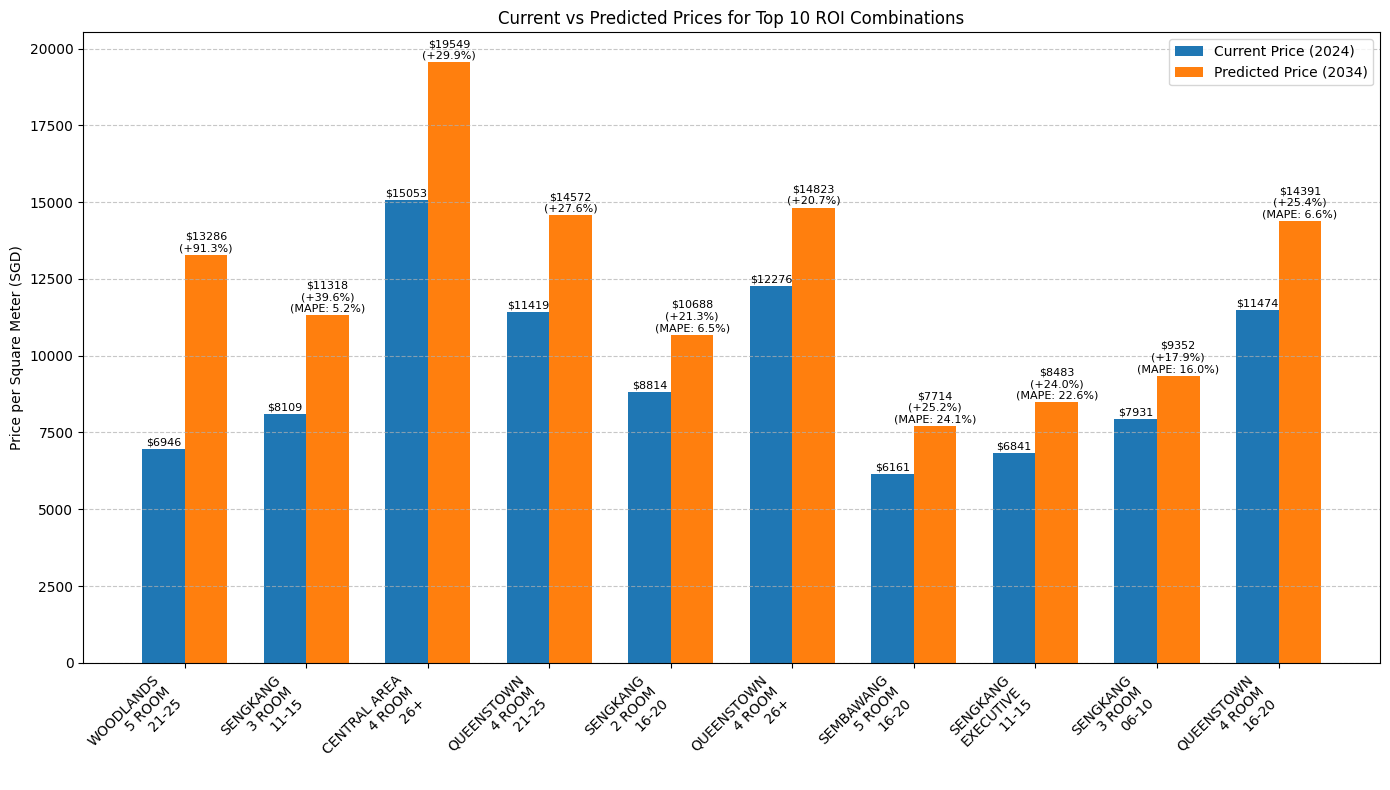


Quadrant Analysis of Top ROI Combinations:


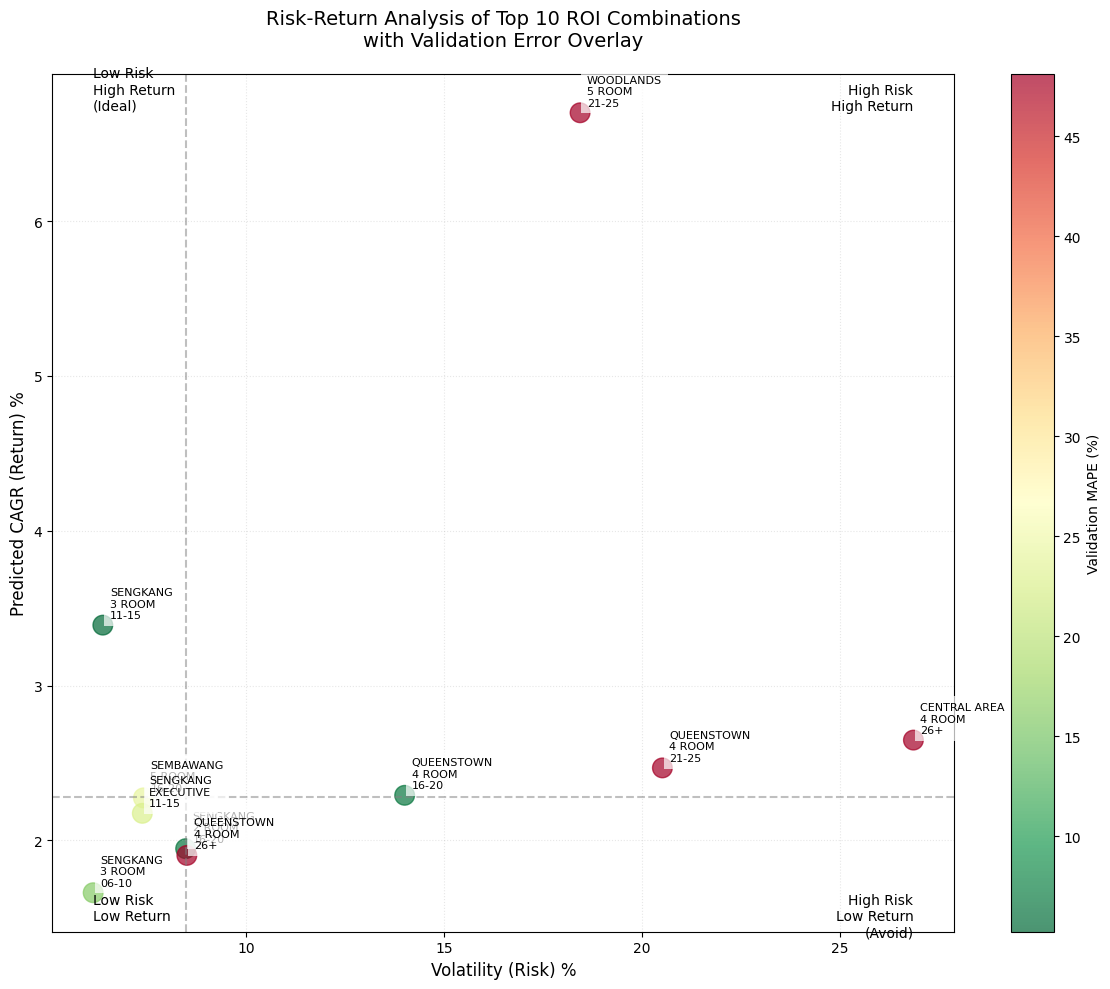


Monte Carlo Price Forecast for Top ROI Combinations:


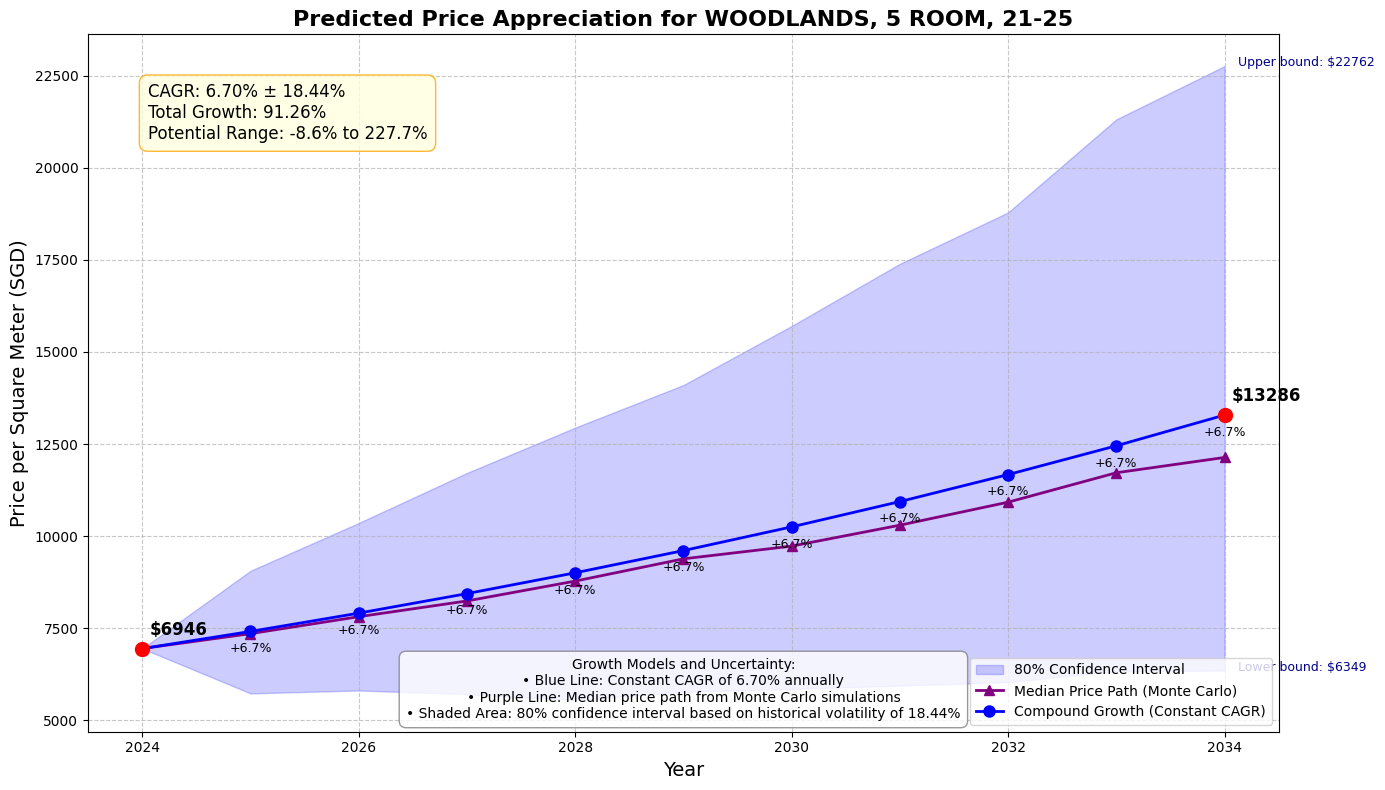

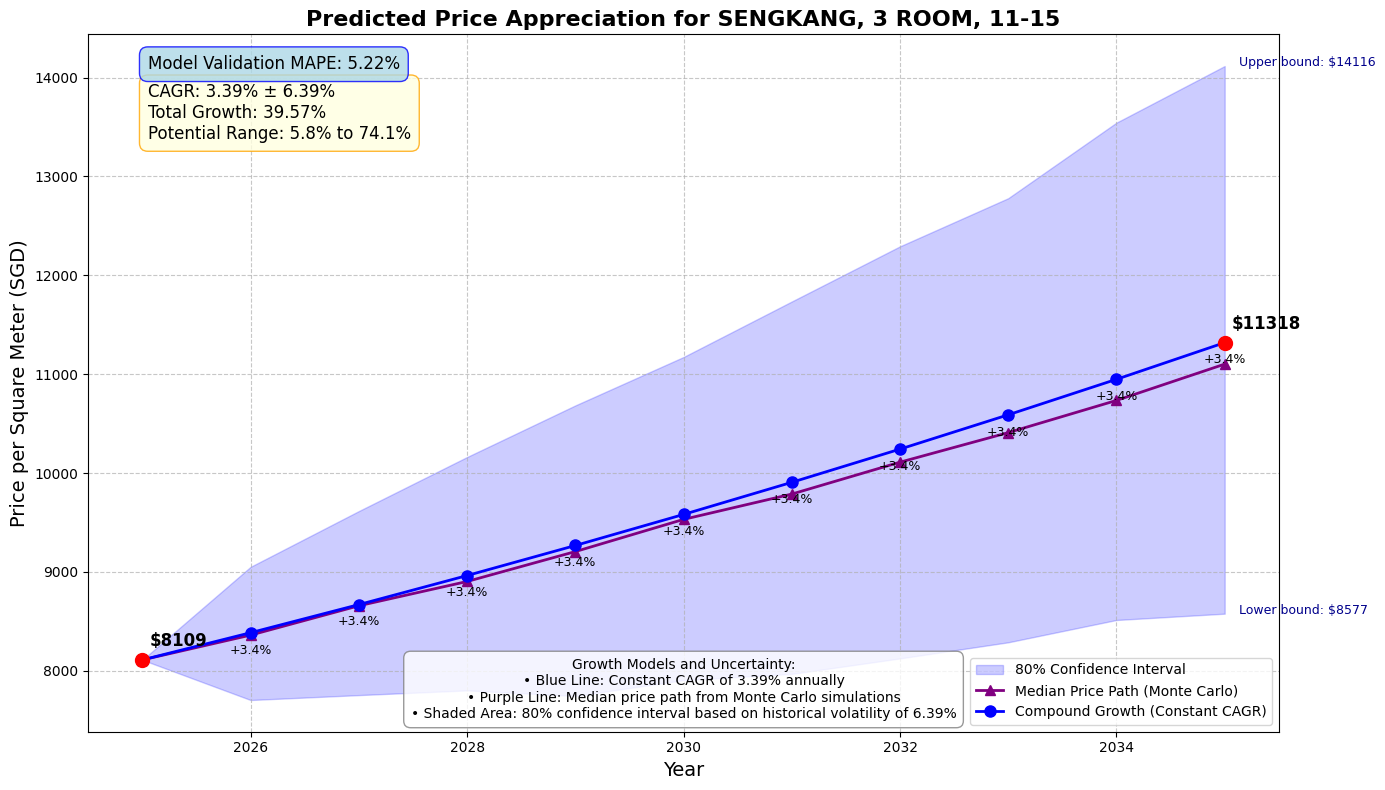


Relationship Between Validation Error and Predicted Growth:


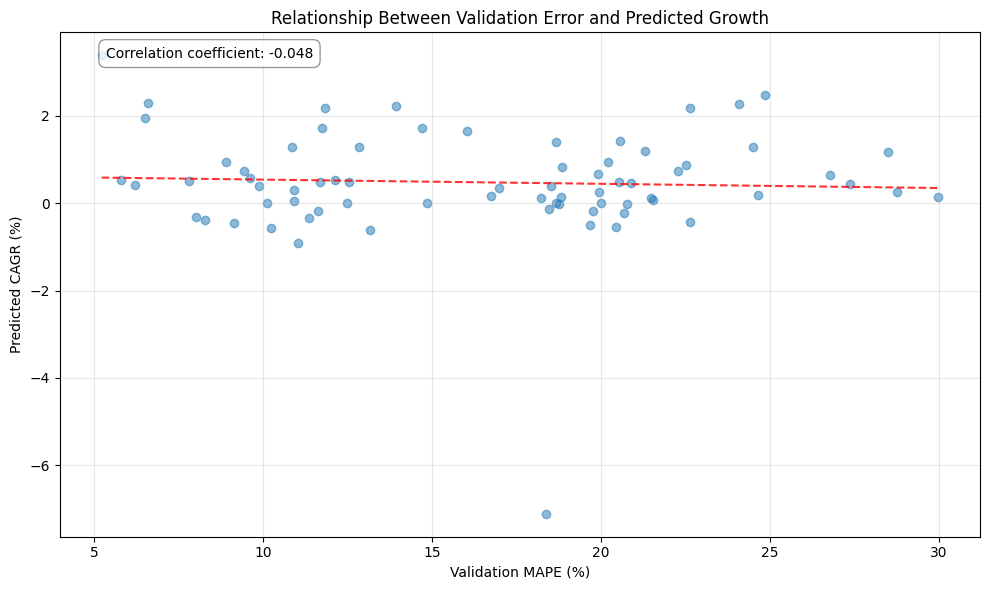

Correlation between validation MAPE and predicted CAGR: -0.048

Distribution of Validation Errors Across All Models:
Found 72 validation MAPE values to plot (out of 104 total rows)


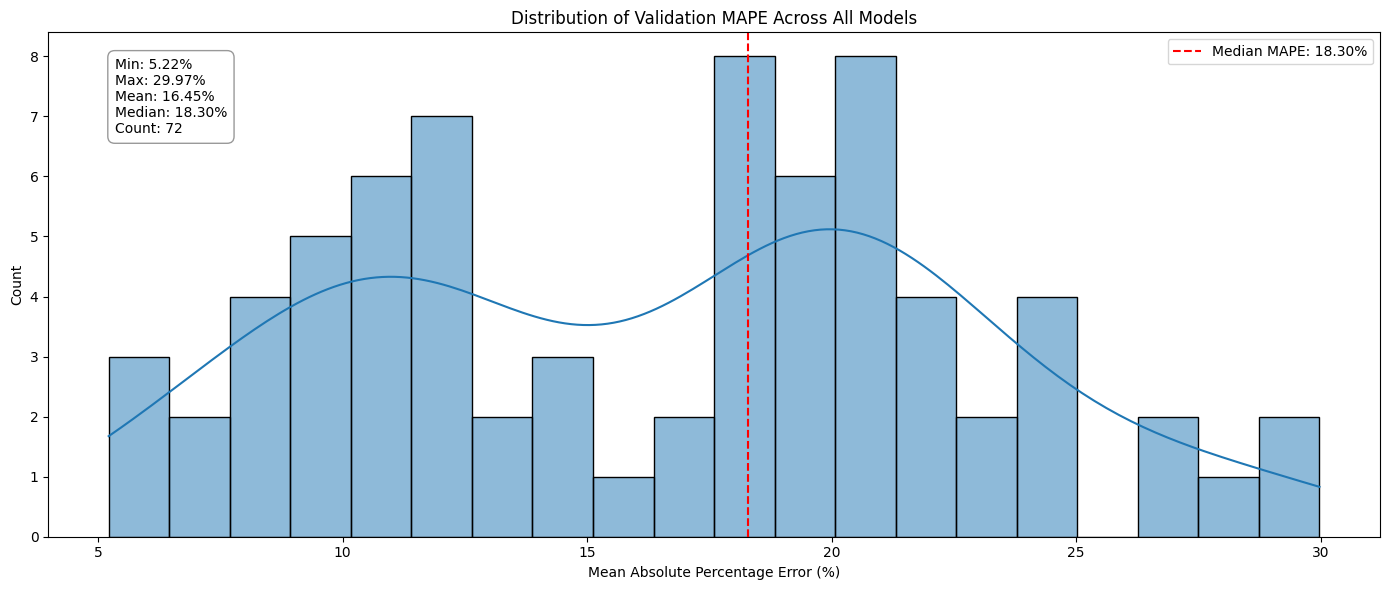

In [6]:
# Main ARIMA analysis workflow designed for Jupyter notebook
print("\nRunning ARIMA models for predicting future prices...")

# First try to load existing predictions
combo_predictions, predictions_df = load_arima_checkpoints()

# If no valid predictions are loaded, generate new ones
if not combo_predictions:
    print("Generating new ARIMA predictions...")

    # Get towns with sufficient historical data
    towns_with_history = find_towns_with_sufficient_history(df_filtered, top_5_towns)

    if not towns_with_history:
        print("No towns have sufficient historical data. ARIMA analysis cannot proceed.")
    else:
        # Generate predictions using ARIMA models
        combo_predictions, predictions_df = generate_arima_predictions(df_filtered, towns_with_history)

# Visualize results if we have predictions
if combo_predictions and not predictions_df.empty:
    # Always reload and merge validation data, regardless of whether it's already in predictions_df
    print("\nLoading and merging validation data...")
    validation_file = os.path.join(config['checkpoint_dir'], 'arima_validation.csv')

    if os.path.exists(validation_file):
        try:
            validation_df = pd.read_csv(validation_file)
            print(f"Found validation data with {len(validation_df)} rows")
            print(f"Validation columns: {validation_df.columns.tolist()}")

            # Check non-null values in mape column
            if 'mape' in validation_df.columns:
                non_null_mape = validation_df['mape'].notna().sum()
                print(f"Non-null MAPE values in validation file: {non_null_mape} out of {len(validation_df)}")

                # Create merge keys
                predictions_df['merge_key'] = predictions_df['town'] + '_' + predictions_df['flat_type'] + '_' + predictions_df['storey_category'].astype(str)
                validation_df['merge_key'] = validation_df['town'] + '_' + validation_df['flat_type'] + '_' + validation_df['storey_category'].astype(str)

                # Find matching keys
                pred_keys = set(predictions_df['merge_key'].unique())
                val_keys = set(validation_df['merge_key'].unique())
                common_keys = pred_keys.intersection(val_keys)
                print(f"Number of matching combinations: {len(common_keys)} out of {len(pred_keys)} prediction combinations")

                # Merge the validation data
                merged_df = pd.merge(predictions_df, validation_df[['merge_key', 'mape', 'rmse']],
                                     on='merge_key', how='left', suffixes=('', '_new'))

                # Update validation columns (overwriting previous values if they exist)
                merged_df['validation_mape'] = merged_df['mape']
                merged_df['validation_rmse'] = merged_df['rmse']

                # Drop temporary columns
                merged_df = merged_df.drop(columns=['merge_key', 'mape', 'rmse'], errors='ignore')

                # Replace the predictions dataframe
                predictions_df = merged_df

                # Verify the validation data is now present
                has_validation_column = 'validation_mape' in predictions_df.columns
                non_null_validation = predictions_df['validation_mape'].notna().sum() if has_validation_column else 0
                print(f"After merging: Found validation_mape column with {non_null_validation} non-null values out of {len(predictions_df)} rows")
            else:
                print("Warning: 'mape' column not found in validation file")
        except Exception as e:
            print(f"Error merging validation data: {str(e)}")
    else:
        print(f"Warning: No validation file found at {validation_file}")

    # Check for validation data availability
    has_validation_data = False
    has_validation_column = 'validation_mape' in predictions_df.columns
    if has_validation_column:
        non_null_validation = predictions_df['validation_mape'].notna().sum()
        if non_null_validation > 0:
            has_validation_data = True
            print(f"Found {non_null_validation} rows with non-null validation data out of {len(predictions_df)} total rows")
        else:
            print("Warning: validation_mape column exists but contains only null values")
    else:
        print("Warning: No validation_mape column found in predictions DataFrame")

    # Find top 10 combinations by predicted ROI
    top_n = 10
    top_predicted_roi = predictions_df.sort_values('predicted_roi_score', ascending=False).head(top_n)

    print(f"\nTop {top_n} Combinations by Predicted ROI (Using ARIMA Model):")

    # Display top combinations in a table
    display_columns = ['town', 'flat_type', 'storey_category', 'current_price',
                       'predicted_price', 'predicted_cagr', 'total_growth_pct',
                       'predicted_roi_score']

    # Add validation metrics to display columns if they exist and have data
    if 'validation_mape' in predictions_df.columns and predictions_df['validation_mape'].notna().any():
        display_columns.append('validation_mape')

    display(top_predicted_roi[display_columns])

    # Show average validation metrics for the top combinations
    if has_validation_data:
        print(f"\nAverage validation metrics for top {top_n} combinations:")
        top_valid_mape = top_predicted_roi['validation_mape'].dropna()
        if len(top_valid_mape) > 0:
            print(f"Mean MAPE: {top_valid_mape.mean():.2f}%")
            print(f"Found {len(top_valid_mape)} out of {len(top_predicted_roi)} top combinations with validation data")
        else:
            print("No valid MAPE values for top combinations.")

        if 'validation_rmse' in top_predicted_roi.columns:
            top_valid_rmse = top_predicted_roi['validation_rmse'].dropna()
            if len(top_valid_rmse) > 0:
                print(f"Mean RMSE: ${top_valid_rmse.mean():.2f}")

    # Create a more detailed table of the top combinations with all metrics
    print("\nDetailed Analysis of Top 10 ROI Combinations (Using ARIMA Prediction):")
    detailed_metrics = top_predicted_roi[['town', 'flat_type', 'storey_category',
                                          'current_price', 'predicted_price', 'total_growth_pct',
                                          'predicted_cagr', 'volatility', 'predicted_sharpe',
                                          'avg_remaining_lease', 'predicted_roi_score']]
    detailed_metrics.columns = ['Town', 'Flat Type', 'Storey Range', 'Current Price/SQM',
                               'Predicted Price/SQM', 'Total Growth %', 'Predicted CAGR %',
                               'Volatility', 'Predicted Sharpe', 'Avg Lease Remaining', 'ROI Score']
    display(detailed_metrics)

    create_visuals = True

else:
    print("Insufficient historical data to generate ARIMA predictions.")
    create_visuals = False

if create_visuals:

    # Plot comparison bar chart of current vs predicted prices
    print("\nCurrent vs Predicted Prices for Top ROI Combinations:")
    plot_comparison_bar_chart(top_predicted_roi)

    # Add the quadrant analysis plot
    print("\nQuadrant Analysis of Top ROI Combinations:")
    plot_top_roi_quadrant_analysis(top_predicted_roi)

    top_combo = top_predicted_roi.iloc[0]

if create_visuals:
    # Plot Monte Carlo forecast for top combination
    print("\nMonte Carlo Price Forecast for Top ROI Combinations:")

    plot_monte_carlo_forecast(top_predicted_roi.iloc[0])
    plot_monte_carlo_forecast(top_predicted_roi.iloc[1])

if create_visuals:

    # Plot validation vs growth relationship
    print("\nRelationship Between Validation Error and Predicted Growth:")
    if has_validation_data:
        correlation = plot_validation_vs_growth(predictions_df)
        if correlation is not None:
            print(f"Correlation between validation MAPE and predicted CAGR: {correlation:.3f}")
    else:
        print("No validation data available to plot MAPE vs. growth relationship.")

    # Plot validation metrics histogram
    print("\nDistribution of Validation Errors Across All Models:")
    if has_validation_data:
        plot_validation_metrics_histogram(predictions_df)
    else:
        print("No validation data available to plot validation error histogram.")

Based on our analysis thus far, here is our conclusion on the optimal ROI combination:

OPTIMAL RECOMMENDATION: SENGKANG 3 ROOM (11-15 STOREY)

Key Advantages:
1.   Balanced Performance Metrics:

  *   Predicted CAGR: 39.57%
  *   Validation MAPE: 5.22% (Excellent accuracy)
  *   ROI Score: 4.67 (Second highest among validated combinations)
  *   Remaining Lease: 88.22 years (Very favorable)


2.   Risk-Return Profile:

  *   Moderate volatility with positive Sharpe ratio (0.108)
  *   Strong historical performance with sustainable growth pattern
  *   Well-balanced between growth potential and stability


3.   Validation Quality:

  *   One of the lowest validation errors (5.22% MAPE)
  *   Significantly better than the average validation MAPE of 13.51%
  *   High confidence in prediction accuracy

4.   Market Fundamentals:

  *   Good transaction volume (sufficient liquidity)
  *   Strong remaining lease period (88+ years)
  *   Mid-floor range (11-15) offers good value proposition

Runner-up Alternative: SENGKANG 2 ROOM (16-20 STOREY)


*   Lower but still attractive growth (21.26%)
*   Excellent validation MAPE of 6.51%
*   High remaining lease (87.93 years)
*   Lower entry price point



Important Considerations:
1.   While WOODLANDS 5 ROOM (21-25) shows the highest ROI score (5.87), it lacks validation data, making it a riskier choice.

2.   The recommended SENGKANG 3 ROOM combination offers the best balance of:
  *   Validated performance
  *   Growth potential
  *   Risk management
  *   Lease duration
  *   Market liquidity

  The long remaining lease period (88+ years) provides good value preservation

  The mid-floor range (11-15) offers a sweet spot between price and desirability